# Phase 5 — FT-Transformer

**Follows:** `05_catboost.ipynb` (tuned CatBoost: val PR-AUC 0.864, the best model so far).

**Why an FT-Transformer:** it is a strong deep-learning architecture for tabular data (Gorishniy et al., 2021). Each feature becomes a learned token, and self-attention lets every feature attend to every other one. Interactions such as *"new merchant **and** online **and** large amount"* are learned directly rather than through tree splits. It is the deep model in this comparison of classic, boosted and deep models.

**Implementation:** `src/ft_transformer.py`, written in plain PyTorch with no extra libraries, so every part is visible:
- **Feature tokenizer.** numeric `x_j → x_j·W_j + b_j`, categorical `level → Embedding_j[level] + b_j`.
- **[CLS] token** + pre-norm Transformer blocks (multi-head attention + ReGLU feed-forward).
- **Head** on the final [CLS] token: LayerNorm → ReLU → Linear.
- **Preprocessing fit on the training sample only.** Quantile-to-normal for the heavy-tailed numeric features (`secs_since_prev_txn` reaches 2.9e7 seconds), binary features unchanged, missing-value indicators, category index 0 for missing/unseen levels.

**Protocol:** the same as every model (`src/evaluation.py`). Fit on undersampled training data, score on the full 2018 validation year, threshold chosen on validation. The 2019 test set isn't loaded. Training runs on the RTX 3060 with bfloat16 mixed precision.

### Resuming after an interruption

Training here takes hours, so nothing is lost if the machine goes off mid-run. **Re-run the notebook from the top** and it continues where it stopped:
- **Each training run** (baseline, every Optuna trial, final refit) saves a checkpoint to `models/checkpoints/ft_transformer/` after every epoch. The checkpoint holds the weights, optimizer state, random-number state, early-stopping state and elapsed time. A re-run picks up at the last finished epoch, so at most one epoch (about 1 minute) is lost. A finished run is loaded straight from its checkpoint without retraining. The test in development showed that a resumed run gives exactly the same validation scores as an uninterrupted one.
- **The Optuna study** is stored in `models/optuna_ft_transformer.db` (SQLite), not in memory. Finished and pruned trials are kept. A trial that was running when the power went off stops sending its heartbeat and is marked failed. Optuna then re-queues it with the same settings, and it resumes from its checkpoint. The 5-hour budget counts time already spent.
- Progress is appended to `models/ft_transformer_run.log` (the notebook's own outputs only appear when it finishes).

To start completely fresh, delete `models/checkpoints/ft_transformer/` and `models/optuna_ft_transformer.db`.

## 0. Setup

In [1]:
import sys, json, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import torch
from sklearn.metrics import average_precision_score

from src.data import PROJECT_ROOT
from src.modeling import TARGET, load_split, feature_sets, undersample
from src.evaluation import evaluate, compare, plot_pr_curves
from src.ft_transformer import TabularPreprocessor, to_device, fit_ft, predict, checkpoint_name

sns.set_style("whitegrid")
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)   # heartbeat API
SEED = 0
MODELS_DIR = PROJECT_ROOT / "models"; MODELS_DIR.mkdir(exist_ok=True)
REPORTS_DIR = PROJECT_ROOT / "reports"
# Crash safety: every training run saves a checkpoint here after each epoch and resumes from it
# if the notebook is re-run (power cut, reboot, closed laptop). See "Resuming after an interruption".
CKPT_DIR = MODELS_DIR / "checkpoints" / "ft_transformer"; CKPT_DIR.mkdir(parents=True, exist_ok=True)
LOG = MODELS_DIR / "ft_transformer_run.log"          # progress you can follow while the notebook runs

def log(msg):
    line = f"{time.strftime('%Y-%m-%d %H:%M:%S')}  {msg}"
    print(line)
    with open(LOG, "a", encoding="utf-8") as f:
        f.write(line + "\n")

print(torch.__version__, torch.cuda.get_device_name(0))

FEATURES = feature_sets()["selected"]
train = load_split("train", FEATURES + ["year"])
val = load_split("val", FEATURES)
y_val = val[TARGET].to_numpy()
print(f"{len(FEATURES)} features | train {len(train):,} rows | val {len(val):,} rows, {y_val.sum():,} frauds")

C:\Users\001\.conda\envs\fraud-detection\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2.11.0+cu128 NVIDIA GeForce RTX 3060


30 features | train 20,604,847 rows | val 1,721,615 rows, 2,491 frauds


In [2]:
# CatBoost's search found that training on 2010+ works best (older years behave differently).
# The same window is used here. The fraud:non-fraud ratio is tuned again, because a neural net
# may react to it differently than boosted trees do.
START_YEAR = 2010
recent = train[train["year"] >= START_YEAR]
del train

_cache = {}
def prepare(neg_per_pos, seed=SEED):
    """Undersample, fit the preprocessor on that sample only, move train + val tensors to the GPU."""
    key = (neg_per_pos, seed)
    if key not in _cache:
        _cache.clear(); torch.cuda.empty_cache()
        s = undersample(recent, neg_per_pos, seed=seed)
        pre = TabularPreprocessor(FEATURES, seed=seed).fit(s)
        tr = to_device(*pre.transform(s), s[TARGET])
        va = to_device(*pre.transform(val), y_val)
        _cache[key] = (pre, tr, va)
    return _cache[key]

pre, tr, va = prepare(100)
print(f"{len(tr[2]):,} training rows | {pre.n_num} numeric tokens + {len(pre.cardinalities)} categorical tokens")
print("missing indicators for:", pre.with_missing)
print("category sizes (incl. missing slot):", dict(zip(pre.cats, pre.cardinalities)))

results, val_scores = {}, {}

1,556,208 training rows | 31 numeric tokens + 3 categorical tokens
missing indicators for: ['secs_since_prev_txn', 'amt_vs_card_mean', 'amt_card_zscore', 'amount_to_limit']
category sizes (incl. missing slot): {'use_chip': 4, 'mcc': 110, 'card_type': 4}


## 1. Baseline: the paper's default configuration

3 blocks, token size 192, 8 heads, attention dropout 0.2, FFN dropout 0.1, AdamW (lr 1e-4, weight decay 1e-5), batch 1024, 1 fraud : 100 non-frauds.

Unlike a tree ensemble, a neural net has no natural stopping point, so the baseline **early-stops on validation PR-AUC** (patience 6 epochs: the curve is noisy from epoch to epoch) and keeps the best epoch. This best-epoch number turns out to be optimistic (see the stabilised final model below).

In [3]:
t0 = time.time()
BASE_CFG = dict(neg_per_pos=100, epochs=40, patience=6, seed=SEED)          # paper defaults otherwise
ft_base, hist_base = fit_ft(tr, pre.n_num, pre.cardinalities, va, epochs=40, patience=6, seed=SEED,
                            checkpoint=CKPT_DIR / checkpoint_name("baseline", BASE_CFG))
val_scores["FT-Transformer (baseline)"] = predict(ft_base, va[0], va[1])
results["FT-Transformer (baseline)"] = evaluate(y_val, val_scores["FT-Transformer (baseline)"])
log(f"baseline: best epoch {ft_base.best_epoch}/{len(hist_base)}, val PR-AUC {max(r['val_pr_auc'] for r in hist_base):.4f}")
compare(results)

  loaded finished run from F:\Data Science Projects\ibm-credit-card-fraud-detection\models\checkpoints\ft_transformer\baseline_6b47240bd5.pt (16 epochs)


2026-11-20 18:25:13  baseline: best epoch 10/16, val PR-AUC 0.7552


,pr_auc,roc_auc,recall@precision0.5,precision@top0.1%,recall@top0.1%,threshold,precision@threshold,recall@threshold,alerts@threshold
FT-Transformer (baseline),0.7552,0.9989,0.8507,0.8031,0.5552,0.7476,0.6586,0.7495,2835.0


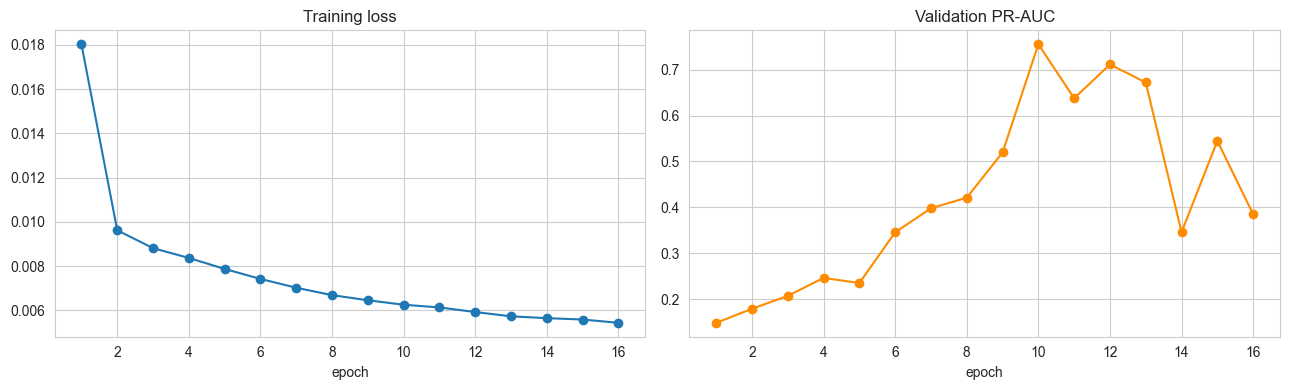

In [4]:
h = pd.DataFrame(hist_base)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
h.plot(x="epoch", y="train_loss", ax=ax[0], marker="o", legend=False, title="Training loss")
h.plot(x="epoch", y="val_pr_auc", ax=ax[1], marker="o", color="darkorange", legend=False, title="Validation PR-AUC")
plt.tight_layout(); plt.show()

## 2. Tuning with Optuna

The search covers architecture size, regularisation, optimiser settings and the undersampling ratio. Every trial early-stops on validation PR-AUC. A test run showed slow learning, about 56 s per epoch with PR-AUC still rising after 12 epochs. Trials are therefore expensive, and two mechanisms keep the search affordable:
- **Pruning.** Each epoch's validation PR-AUC is reported to Optuna. A trial that falls below the median of earlier trials at the same epoch (after an 8-epoch warm-up) is stopped.
- **Caps.** Each trial is limited to `TRIAL_MAX_MIN` minutes, and the whole search has a time budget.

In [5]:
TIME_BUDGET_H = 5
TRIAL_MAX_MIN = 30

def ft_objective(trial):
    neg_per_pos = trial.suggest_categorical("neg_per_pos", [40, 100, 200])
    params = dict(
        d_token=trial.suggest_categorical("d_token", [64, 128, 192, 256]),
        n_blocks=trial.suggest_int("n_blocks", 1, 4),
        attn_dropout=trial.suggest_float("attn_dropout", 0.0, 0.5),
        ffn_dropout=trial.suggest_float("ffn_dropout", 0.0, 0.5),
        residual_dropout=trial.suggest_float("residual_dropout", 0.0, 0.2),
        lr=trial.suggest_float("lr", 3e-5, 1e-3, log=True),
        weight_decay=trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        batch_size=trial.suggest_categorical("batch_size", [512, 1024, 2048]),
    )
    pre, tr, va = prepare(neg_per_pos)
    # Checkpoint named after the settings: a re-queued trial (same settings) finds and resumes it
    ckpt = CKPT_DIR / checkpoint_name("trial", trial.params)
    def report(epoch, ap):
        trial.report(ap, epoch)
        if trial.should_prune():
            ckpt.unlink(missing_ok=True)
            log(f"trial {trial.number}: pruned at epoch {epoch} (PR-AUC {ap:.4f})  {trial.params}")
            raise optuna.TrialPruned()
    model, hist = fit_ft(tr, pre.n_num, pre.cardinalities, va, epochs=40, patience=6, seed=SEED,
                         verbose=False, max_minutes=TRIAL_MAX_MIN, on_epoch=report, checkpoint=ckpt, **params)
    trial.set_user_attr("best_epoch", model.best_epoch)
    trial.set_user_attr("epochs_run", len(hist))
    trial.set_user_attr("minutes", sum(r["secs"] for r in hist) / 60)
    best = max(r["val_pr_auc"] for r in hist)
    log(f"trial {trial.number}: PR-AUC {best:.4f}  (epoch {model.best_epoch}/{len(hist)})  {trial.params}")
    del model; torch.cuda.empty_cache()
    ckpt.unlink(missing_ok=True)          # the result is now in the study database
    return best

N_TRIALS = 30
# Persistent study: survives a power cut. The heartbeat lets Optuna notice a trial that died
# mid-run; RetryFailedTrialCallback re-queues it with the same settings (it then resumes from its checkpoint).
storage = optuna.storages.RDBStorage(
    f"sqlite:///{(MODELS_DIR / 'optuna_ft_transformer.db').as_posix()}",
    heartbeat_interval=60, grace_period=180,
    heartbeat_stale_trial_callback=optuna.storages.RetryHeartbeatStaleTrialCallback(max_retry=3))
ft_study = optuna.create_study(study_name="ft_transformer", storage=storage, load_if_exists=True,
                               direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED),
                               pruner=optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=8))
# Start from the paper's defaults (the baseline), so the search can only improve on them
ft_study.enqueue_trial(dict(neg_per_pos=100, d_token=192, n_blocks=3, attn_dropout=0.2, ffn_dropout=0.1,
                            residual_dropout=0.0, lr=1e-4, weight_decay=1e-5, batch_size=1024),
                       skip_if_exists=True)

# Budget counts work already done in earlier (interrupted) sessions. Only completed/pruned trials:
# a trial killed by a power cut is stamped 'failed' when the restart notices it, so its duration
# would include the downtime.
done = [t for t in ft_study.trials if t.state.name in ("COMPLETE", "PRUNED")]
spent_s = sum((t.datetime_complete - t.datetime_start).total_seconds() for t in done if t.datetime_start)
counted = len(done)
remaining_s = TIME_BUDGET_H * 3600 - spent_s
log(f"study: {counted} trials done, {spent_s / 3600:.2f} h spent, {max(remaining_s, 0) / 3600:.2f} h left")
if remaining_s > 0 and counted < N_TRIALS:
    ft_study.optimize(ft_objective, n_trials=N_TRIALS - counted, timeout=remaining_s,
                      catch=(torch.OutOfMemoryError,))     # a too-large config fails, the search continues
best = {**ft_study.best_params, "epochs": ft_study.best_trial.user_attrs["best_epoch"]}
log(f"study finished: {len(ft_study.trials)} trials | best val PR-AUC {ft_study.best_value:.4f} | {best}")
best

2026-11-20 18:25:14  study: 19 trials done, 5.33 h spent, 0.00 h left
2026-11-20 18:25:14  study finished: 19 trials | best val PR-AUC 0.7552 | {'neg_per_pos': 100, 'd_token': 192, 'n_blocks': 3, 'attn_dropout': 0.2, 'ffn_dropout': 0.1, 'residual_dropout': 0.0, 'lr': 0.0001, 'weight_decay': 1e-05, 'batch_size': 1024, 'epochs': 10}


{'neg_per_pos': 100,
 'd_token': 192,
 'n_blocks': 3,
 'attn_dropout': 0.2,
 'ffn_dropout': 0.1,
 'residual_dropout': 0.0,
 'lr': 0.0001,
 'weight_decay': 1e-05,
 'batch_size': 1024,
 'epochs': 10}

In [6]:
ft_trials = ft_study.trials_dataframe()
print(ft_trials["state"].value_counts().to_dict())
cols = ["number", "value", "user_attrs_best_epoch", "user_attrs_epochs_run", "user_attrs_minutes"] + \
       [c for c in ft_trials.columns if c.startswith("params_")]
ft_trials[cols].sort_values("value", ascending=False).head(10)

{'PRUNED': 13, 'COMPLETE': 6}


,number,value,user_attrs_best_epoch,user_attrs_epochs_run,user_attrs_minutes,params_attn_dropout,params_batch_size,params_d_token,params_ffn_dropout,params_lr,params_n_blocks,params_neg_per_pos,params_residual_dropout,params_weight_decay
0,0,0.755215,10.0,16.0,14.713912,0.200000,1024,192,0.100000,0.000100,3,100,0.000000,0.000010
3,3,0.689560,16.0,18.0,23.739561,0.179754,512,256,0.218516,0.000037,3,100,0.139526,0.000100
18,18,0.683264,12.0,18.0,17.642733,0.261353,512,192,0.058514,0.000063,3,100,0.046319,0.000013
13,13,0.682633,12.0,18.0,23.668513,0.104392,512,256,0.367094,0.000048,3,100,0.106160,0.000191
1,1,0.477823,9.0,15.0,19.657854,0.481831,512,192,0.191721,0.000192,4,100,0.158345,0.000051
10,10,0.465798,NaN,NaN,NaN,0.344867,1024,128,0.008714,0.000050,4,100,0.009934,0.000006
2,2,0.464339,16.0,22.0,18.939483,0.059137,2048,128,0.319961,0.000824,4,100,0.028671,0.000037
15,15,0.372128,NaN,NaN,NaN,0.035732,512,256,0.193311,0.000091,3,100,0.007207,0.000006
16,16,0.319478,NaN,NaN,NaN,0.363223,1024,192,0.185946,0.000138,4,100,0.000054,0.000004
14,14,0.311102,NaN,NaN,NaN,0.183364,1024,192,0.164916,0.000099,3,100,0.145014,0.000240


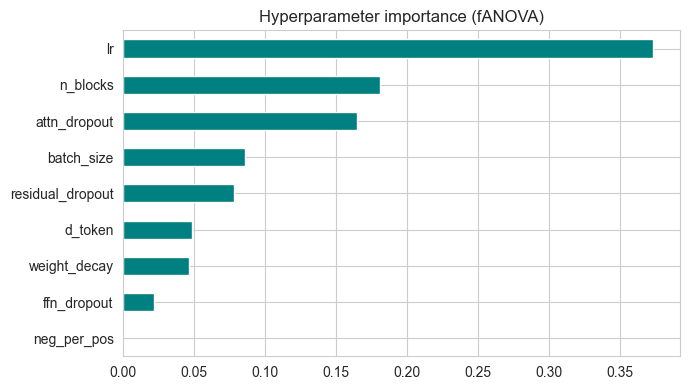

In [7]:
if sum(t.state.name == "COMPLETE" for t in ft_study.trials) >= 4:   # fANOVA uses completed trials only
    imp = pd.Series(optuna.importance.get_param_importances(
        ft_study, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEED)))
    imp.sort_values().plot(kind="barh", figsize=(7, 4), color="teal")
    plt.title("Hyperparameter importance (fANOVA)")
    plt.tight_layout(); plt.show()

### Final tuned model: stabilised training

The search kept the paper's settings, but the baseline's 0.755 comes from picking the luckiest epoch of a very noisy curve. The final model therefore uses the same settings with three standard stabilisers. **The recipe was fixed before any of these runs and isn't tuned on validation:**
- **Learning-rate schedule.** Linear warm-up over 1 epoch, then cosine decay to 0 over a fixed **20 epochs**. With constant lr the weights keep jumping; a decaying lr lets them settle.
- **Exponential moving average (EMA) of the weights** (decay 0.9995, ≈ the last 1.3 epochs of updates). The model that is evaluated is the averaged one, not the last noisy step.
- **No best-epoch selection.** The model after the last epoch is the model. Validation PR-AUC is still recorded every epoch, but only to plot the curve.
- **3 seeds** (model initialisation and batch order; same training sample and preprocessor). Each seed is reported, and the final "tuned" score is the **average of the 3 seeds' probabilities**.

So the validation number below is an honest estimate, unlike the baseline's best-epoch number. Each run checkpoints every epoch like the rest of the notebook (≈ 20 min per seed).


In [8]:
STABLE = dict(epochs=20, schedule="cosine", warmup_epochs=1, ema_decay=0.9995, select_best=False)
SEEDS = [0, 1, 2]
pre, tr, va = prepare(best["neg_per_pos"])
fit_params = {k: v for k, v in best.items() if k not in ("neg_per_pos", "epochs")}

ft_seeds, hist_seeds, seed_scores = [], {}, {}
for s in SEEDS:
    t0 = time.time()
    cfg = {**fit_params, **STABLE, "neg_per_pos": best["neg_per_pos"], "seed": s}
    m, h = fit_ft(tr, pre.n_num, pre.cardinalities, va, seed=s,
                  checkpoint=CKPT_DIR / checkpoint_name("stable", cfg), **STABLE, **fit_params)
    ft_seeds.append(m); hist_seeds[s] = h
    seed_scores[s] = predict(m, va[0], va[1])
    log(f"stable seed {s}: final-epoch val PR-AUC {h[-1]['val_pr_auc']:.4f}  ({time.time() - t0:.0f}s)")

seed_ap = pd.Series({s: average_precision_score(y_val, p) for s, p in seed_scores.items()}, name="val_pr_auc")
print(f"single seeds: {seed_ap.round(4).to_dict()} | mean {seed_ap.mean():.4f} ± {seed_ap.std():.4f} (std)")
val_scores["FT-Transformer (tuned)"] = np.mean([seed_scores[s] for s in SEEDS], axis=0)
results["FT-Transformer (tuned)"] = evaluate(y_val, val_scores["FT-Transformer (tuned)"])
log(f"stable 3-seed average: val PR-AUC {results['FT-Transformer (tuned)']['pr_auc']:.4f}")
compare(results)


  epoch 1 | train_loss 0.0536 | secs 55.0068 | val_pr_auc 0.1221


  epoch 2 | train_loss 0.0105 | secs 55.6107 | val_pr_auc 0.1663


  epoch 3 | train_loss 0.0092 | secs 55.2830 | val_pr_auc 0.2121


  epoch 4 | train_loss 0.0085 | secs 55.1881 | val_pr_auc 0.2561


  epoch 5 | train_loss 0.0079 | secs 55.1965 | val_pr_auc 0.3046


  epoch 6 | train_loss 0.0076 | secs 55.3040 | val_pr_auc 0.3452


... (56 outputs left out)

2026-11-20 19:37:45  stable seed 2: final-epoch val PR-AUC 0.4349  (1435s)


single seeds: {0: 0.5641, 1: 0.494, 2: 0.4349} | mean 0.4977 ± 0.0647 (std)


2026-11-20 19:37:46  stable 3-seed average: val PR-AUC 0.5328


,pr_auc,roc_auc,recall@precision0.5,precision@top0.1%,recall@top0.1%,threshold,precision@threshold,recall@threshold,alerts@threshold
FT-Transformer (baseline),0.7552,0.9989,0.8507,0.8031,0.5552,0.7476,0.6586,0.7495,2835.0
FT-Transformer (tuned),0.5328,0.9910,0.5243,0.6231,0.4308,0.4989,0.5817,0.4629,1982.0


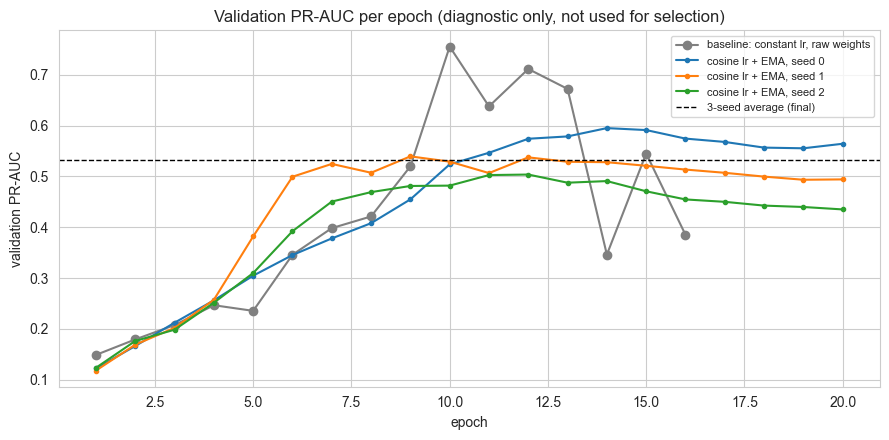

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
hb = pd.DataFrame(hist_base)
ax.plot(hb["epoch"], hb["val_pr_auc"], marker="o", color="grey", label="baseline: constant lr, raw weights")
for s, h in hist_seeds.items():
    h = pd.DataFrame(h)
    ax.plot(h["epoch"], h["val_pr_auc"], marker=".", label=f"cosine lr + EMA, seed {s}")
ax.axhline(results["FT-Transformer (tuned)"]["pr_auc"], ls="--", color="black", lw=1, label="3-seed average (final)")
ax.set(xlabel="epoch", ylabel="validation PR-AUC", title="Validation PR-AUC per epoch (diagnostic only, not used for selection)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()


## 3. Comparison with the earlier models

C:\Users\001\AppData\Local\Temp\ipykernel_24836\3641209279.py:17: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout(); plt.show()


C:\Users\001\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


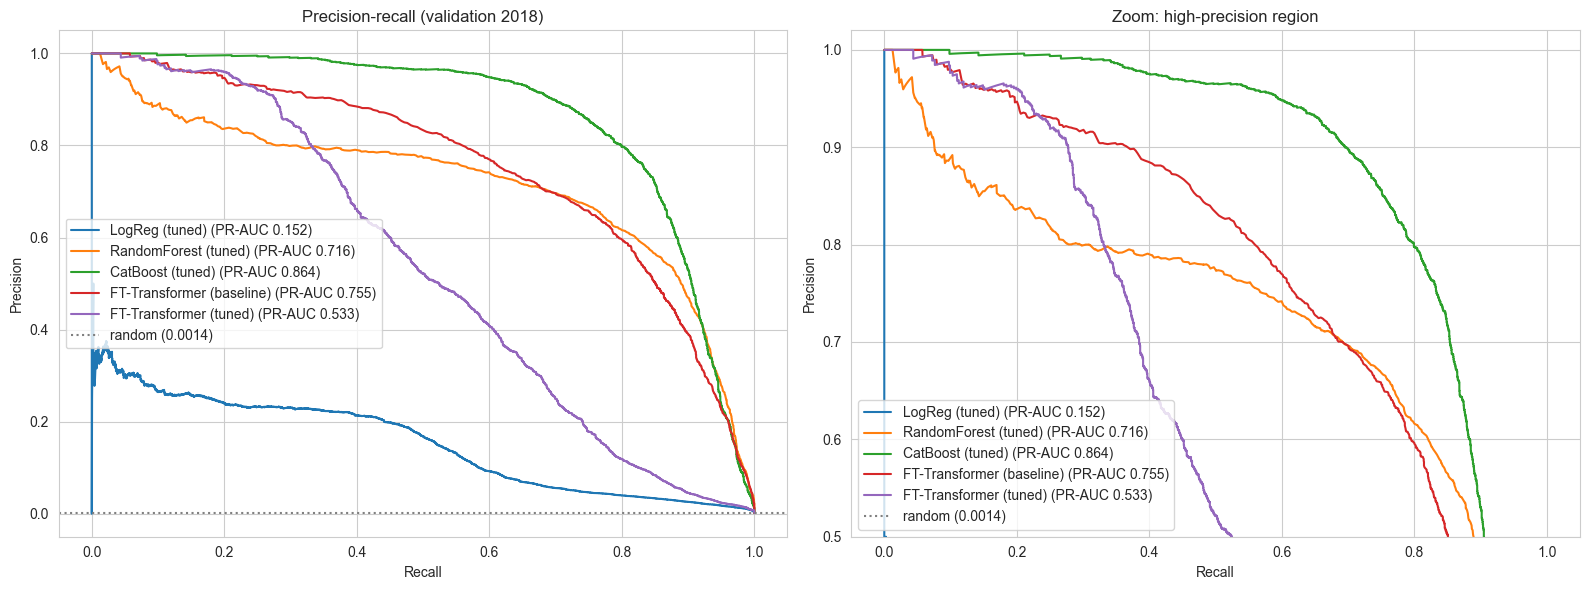

,pr_auc,roc_auc,recall@precision0.5,precision@top0.1%,recall@top0.1%,threshold,precision@threshold,recall@threshold,alerts@threshold
LogReg (tuned),0.1521,0.9825,0.0024,0.2515,0.1738,0.9787,0.2104,0.4287,5076.0
RandomForest (tuned),0.7155,0.9990,0.8888,0.7648,0.5287,0.5780,0.6653,0.7563,2832.0
CatBoost (tuned),0.8636,0.9989,0.9049,0.9338,0.6455,0.4993,0.8198,0.7836,2381.0
FT-Transformer (baseline),0.7552,0.9989,0.8507,0.8031,0.5552,0.7476,0.6586,0.7495,2835.0
FT-Transformer (tuned),0.5328,0.9910,0.5243,0.6231,0.4308,0.4989,0.5817,0.4629,1982.0


In [10]:
cache = PROJECT_ROOT / "data" / "cache"
trad = pd.read_parquet(cache / "val_scores_traditional.parquet")
cb = pd.read_parquet(cache / "val_scores_catboost.parquet")
all_scores = {"LogReg (tuned)": trad["LogReg (tuned)"].to_numpy(),
              "RandomForest (tuned)": trad["RandomForest (tuned)"].to_numpy(),
              "CatBoost (tuned)": cb["CatBoost (tuned)"].to_numpy(),
              **val_scores}
all_results = pd.concat([
    pd.read_csv(REPORTS_DIR / "val_metrics_traditional.csv", index_col=0).loc[["LogReg (tuned)", "RandomForest (tuned)"]],
    pd.read_csv(REPORTS_DIR / "val_metrics_catboost.csv", index_col=0).loc[["CatBoost (tuned)"]],
    compare(results)])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_pr_curves(y_val, all_scores, ax=axes[0])
plot_pr_curves(y_val, all_scores, ax=axes[1], title="Zoom: high-precision region")
axes[1].set_ylim(0.5, 1.02)
plt.tight_layout(); plt.show()
all_results

### Do CatBoost and the FT-Transformer make the same mistakes?

If the two models rank transactions differently, averaging their scores can beat both. This is a quick check, not a tuned ensemble: the blend weight is not chosen on validation, so this validation number stays honest.

In [11]:
from scipy.stats import rankdata, spearmanr
cb_s, ft_s = all_scores["CatBoost (tuned)"], val_scores["FT-Transformer (tuned)"]
fraud = y_val == 1
print(f"Spearman rank correlation, all transactions: {spearmanr(cb_s, ft_s)[0]:.3f}")
print(f"Spearman rank correlation, frauds only:      {spearmanr(cb_s[fraud], ft_s[fraud])[0]:.3f}")
blend = (rankdata(cb_s) + rankdata(ft_s)) / (2 * len(cb_s))     # equal-weight rank average
print(f"PR-AUC  CatBoost {average_precision_score(y_val, cb_s):.4f} | FT {average_precision_score(y_val, ft_s):.4f} | "
      f"50/50 rank blend {average_precision_score(y_val, blend):.4f}")

Spearman rank correlation, all transactions: 0.612
Spearman rank correlation, frauds only:      0.652


PR-AUC  CatBoost 0.8636 | FT 0.5328 | 50/50 rank blend 0.6632


### Findings

**The FT-Transformer is third, behind CatBoost and the Random Forest.** The final model (3 seeds, cosine lr + EMA, fixed 20 epochs, averaged) reaches val PR-AUC **0.533**, compared with 0.864 for tuned CatBoost, 0.716 for the tuned Random Forest and 0.152 for logistic regression. Single seeds score 0.564, 0.494 and 0.435 (mean 0.498 ± 0.065). At the validation-chosen threshold it raises 1,982 alerts with precision 0.58 and recall 0.46.

**The baseline's 0.755 was a lucky epoch.** With a constant learning rate, validation PR-AUC jumped by 0.2–0.4 between consecutive epochs (0.52 → **0.76** → 0.64 → 0.71 → 0.67 → 0.35 over epochs 9–14). Keeping "the best epoch" picked that spike. The stabilisers removed the jumps: the curves are now smooth, and they show the real picture:
- Every seed **peaks around epochs 12–14 at about 0.50–0.59, then declines slowly**, while the training loss keeps falling. The model fits the 2010–2017 training years too closely, and 2018 has drifted enough that this hurts.
- The recipe (20 epochs, EMA 0.9995, last epoch) was fixed **before** these runs, and the epoch count was deliberately **not** re-chosen after seeing the curves. Doing so would gain a few hundredths at most and would turn validation into a tuning set again.
- The baseline row is kept in the table as a warning: best-epoch selection on a noisy validation curve overstated this model by about 0.2 PR-AUC.

**Tuning didn't beat the paper's default settings.** The search ran **19 trials in its 5-hour budget: 6 completed and 13 pruned**. The best trial is the enqueued default configuration, which the final model uses.
- **1 : 100 is the right ratio here too.** All four 1:200 trials and the single 1:40 trial were pruned.
- **Heavy dropout, high learning rates and 1–2 block models did worse.**
- These comparisons were made on the noisy best-epoch numbers. The median pruner judged trials at epoch 8, before most runs' jump around epochs 9–12, so with only 19 trials the search can't reliably separate configurations.

**Blending with CatBoost hurts.** The two models' rankings agree only moderately (Spearman 0.61 overall, 0.65 on frauds). An equal-weight rank blend scores 0.663, well below CatBoost's 0.864. The FT-Transformer doesn't catch frauds that CatBoost misses.

**Conclusion.** On this data, with these features, a well-implemented FT-Transformer is clearly beaten by gradient-boosted trees, which matches the general finding for tabular data (Grinsztajn et al., 2022). The final FT-Transformer is the 3-seed stabilised model. It goes into the ablations and the single test evaluation as it is.


## 4. Save

In [12]:
torch.save({"state_dicts": [m.state_dict() for m in ft_seeds],
            "params": {**best, **STABLE, "seeds": SEEDS}, "preprocessor": pre},
           MODELS_DIR / "ft_transformer_tuned.pt")
compare(results).to_csv(REPORTS_DIR / "val_metrics_ft_transformer.csv")
(REPORTS_DIR / "best_params_ft_transformer.json").write_text(json.dumps(
    {"ft_transformer": {"params": {**best, **STABLE}, "seeds": SEEDS, "start_year": START_YEAR,
                        "val_pr_auc_per_seed": seed_ap.round(4).to_dict(),
                        "val_threshold": results["FT-Transformer (tuned)"]["threshold"]}}, indent=2, default=str))
ft_trials[cols].to_csv(REPORTS_DIR / "optuna_trials_ft_transformer.csv", index=False)
pd.DataFrame(val_scores).astype("float32").to_parquet(PROJECT_ROOT / "data" / "cache" / "val_scores_ft_transformer.parquet")
print("Saved model (3 seeds), params, trials and validation metrics.")


Saved model (3 seeds), params, trials and validation metrics.
